# Segmentação de Clientes com RFM e K-Means

**Trabalho de Conclusão de Curso — Especialização em Ciência de Dados, UTFPR**

Autor: Alceu Pantoni Neto

Este notebook implementa a segmentação de clientes de um e-commerce a partir do histórico de transações, utilizando a análise RFM (Recência, Frequência, Valor monetário) combinada ao algoritmo K-Means. O objetivo é agrupar os clientes por comportamento de compra e associar uma ação de marketing a cada segmento identificado.

**Dataset:** [Online Retail (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/352/online+retail) — transações de um e-commerce do Reino Unido entre dezembro de 2010 e dezembro de 2011.

## 1. Configuração do ambiente

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import seaborn as sns

from segmentacao.data import carregar_transacoes
from segmentacao.rfm import limpar_transacoes, calcular_rfm
from segmentacao.clustering import preparar_features, avaliar_k, segmentar
from segmentacao.labeling import classificar_segmentos

## 2. Carregamento dos dados

Os dados são baixados automaticamente do UCI Machine Learning Repository (se
ainda não existirem localmente) e carregados em um DataFrame do pandas.

In [2]:
df = carregar_transacoes()
print(f"Transações carregadas: {df.shape[0]} linhas, {df.shape[1]} colunas")
df.head()

Dataset já existe no projeto, pulando download.
Transações carregadas: 541909 linhas, 8 colunas


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 3. Limpeza dos dados e cálculo do RFM

Antes de calcular os indicadores por cliente, removemos registros sem
identificação de cliente (`CustomerID` nulo), devoluções (faturas com prefixo
"C") e linhas com quantidade ou preço não positivos.

Para cada cliente, calculamos:
- **Recência**: dias desde a última compra
- **Frequência**: número de pedidos distintos
- **Valor**: soma total gasta

In [3]:
df_limpo = limpar_transacoes(df)
print(f"Linhas antes da limpeza: {len(df)}")
print(f"Linhas após a limpeza: {len(df_limpo)}")

rfm = calcular_rfm(df_limpo)
print(f"Clientes únicos: {rfm.shape[0]}")
rfm.describe()

Linhas antes da limpeza: 541909
Linhas após a limpeza: 397884
Clientes únicos: 4338


,Recencia,Frequencia,Valor
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


Os dados de Frequência e Valor apresentam forte assimetria à direita — poucos clientes concentram volumes muito altos de compra, enquanto a maioria compra pouco. Essa característica, comum em dados de varejo, orienta a escolha metodológica da próxima etapa: a aplicação de transformação logarítmica antes da normalização, de modo que o K-Means (que utiliza distância euclidiana) não seja dominado pelos valores extremos.

## 4. Segmentação com K-Means

### 4.1 Preparação das variáveis e escolha do número de grupos

As variáveis RFM são transformadas com log(1+x) e normalizadas (z-score). Em seguida, avaliamos o número ideal de grupos (k) no intervalo de 2 a 10, utilizando o método do cotovelo (inércia) e o coeficiente de silhueta.

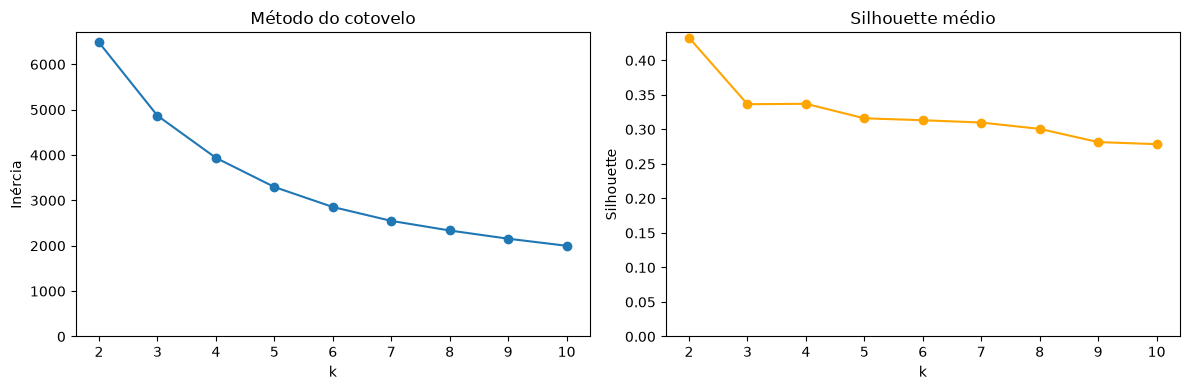

,k,inertia,silhouette
0,2,6481.225323,0.432940
1,3,4867.846645,0.336510
2,4,3938.509954,0.337134
3,5,3295.976329,0.316097
4,6,2855.011247,0.313329
5,7,2548.914324,0.309975
6,8,2336.777508,0.300782
7,9,2155.648193,0.281653
8,10,1999.903270,0.278665


In [4]:
X = preparar_features(rfm)
metricas = avaliar_k(X, k_min=2, k_max=10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(metricas["k"], metricas["inertia"], marker="o")
ax1.set_title("Método do cotovelo")
ax1.set_xlabel("k"); ax1.set_ylabel("Inércia")
ax1.set_ylim(bottom=0)

ax2.plot(metricas["k"], metricas["silhouette"], marker="o", color="orange")
ax2.set_title("Silhouette médio")
ax2.set_xlabel("k"); ax2.set_ylabel("Silhouette")
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig("outputs/figuras/cotovelo_silhouette.png", dpi=150)
plt.show()

metricas

O coeficiente de silhueta é máximo em k=2 (0,43), mas esse valor resultaria em apenas dois grupos amplos, pouco úteis para diferenciar ações de marketing. A partir de k=3, o silhueta estabiliza entre 0,28 e 0,34, e a curva de inércia (cotovelo) começa a perder inclinação de forma mais acentuada nesse intervalo.

Optou-se por **k=5**, que mantém o coeficiente de silhueta (0,316) acima do limite mínimo estabelecido (0,30) e oferece granularidade suficiente para caracterizar perfis de cliente distintos e acionáveis.

### 4.2 Segmentação final

In [5]:
rotulos, modelo = segmentar(X, k=5)
rfm["Segmento"] = rotulos

## 5. Caracterização e nomeação dos segmentos

Cada segmento é nomeado e associado a uma ação de marketing a partir da comparação relativa entre as médias de RFM dos cinco grupos (ver `classificar_segmentos` no código-fonte do projeto, em `src/segmentacao/labeling.py`).

In [6]:
perfil_medio = rfm.groupby("Segmento")[["Recencia", "Frequencia", "Valor"]].mean()
perfil_nomeado = classificar_segmentos(perfil_medio)

rfm_final = rfm.merge(
    perfil_nomeado[["Nome", "Acao"]], left_on="Segmento", right_index=True
)

perfil_nomeado

,Recencia,Frequencia,Valor,Nome,Acao
Segmento,,,,,
0,27.988249,1.613396,389.042844,Novos,E-mail de boas-vindas e incentivo à compra
1,18.547669,5.797669,2168.931155,Fiéis,Cross-sell e incentivo para virar campeão
2,211.147679,1.212658,277.204811,Hibernando,Campanha de reengajamento de baixo custo
3,12.189504,20.626822,13780.075510,Campeões,Programa de fidelidade e acesso antecipado a l...
4,104.142857,3.127094,1455.968308,Em risco,Cupom de reativação e contato personalizado


## 6. Visualizações

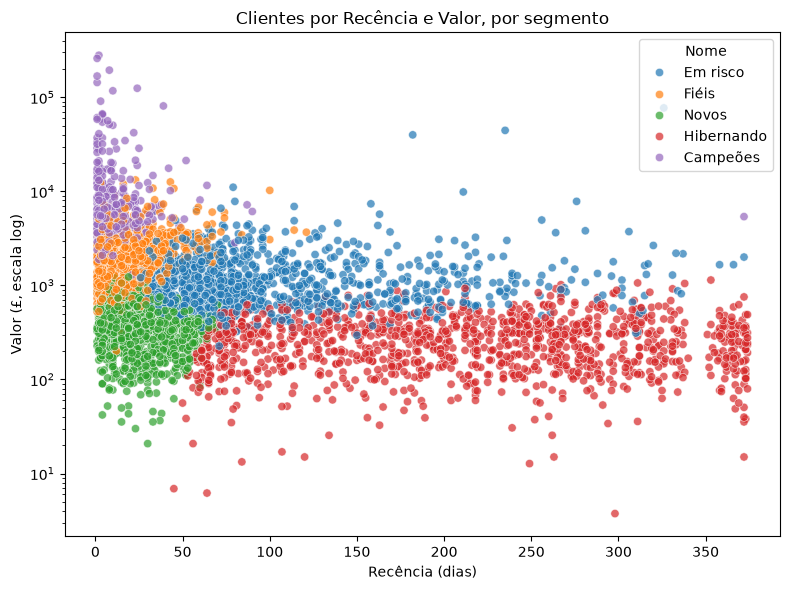

In [7]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=rfm_final, x="Recencia", y="Valor", hue="Nome", alpha=0.7)
plt.yscale("log")
plt.title("Clientes por Recência e Valor, por segmento")
plt.xlabel("Recência (dias)")
plt.ylabel("Valor (£, escala log)")
plt.tight_layout()
plt.savefig("outputs/figuras/dispersao_segmentos.png", dpi=150)
plt.show()

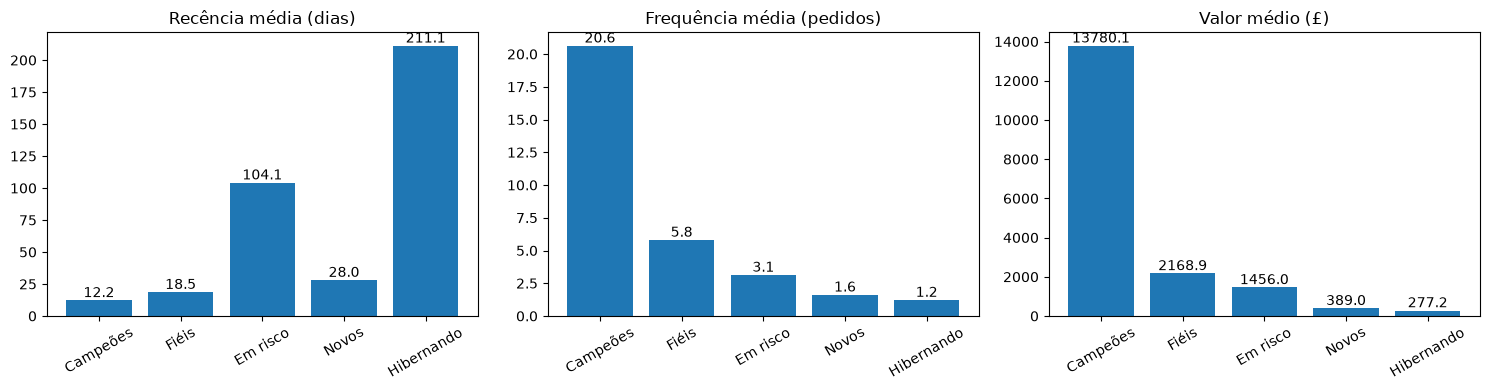

In [8]:
ordem = perfil_nomeado.sort_values("Valor", ascending=False)["Nome"]
perfil_por_nome = perfil_nomeado.set_index("Nome").loc[ordem]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(
    axes, ["Recencia", "Frequencia", "Valor"],
    ["Recência média (dias)", "Frequência média (pedidos)", "Valor médio (£)"],
):
    barras = ax.bar(perfil_por_nome.index, perfil_por_nome[coluna])
    ax.bar_label(barras, fmt="%.1f", label_type="edge", color="black")
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("outputs/figuras/perfil_segmentos.png", dpi=150)
plt.show()

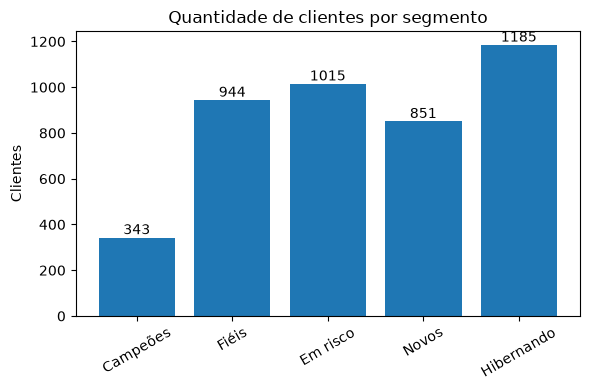

In [9]:
tamanhos = rfm_final["Nome"].value_counts().reindex(ordem)

plt.figure(figsize=(6, 4))
barras = plt.bar(tamanhos.index, tamanhos.to_numpy())
plt.bar_label(barras, fmt="%d", label_type="edge", color="black")
plt.title("Quantidade de clientes por segmento")
plt.ylabel("Clientes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("outputs/figuras/tamanho_segmentos.png", dpi=150)
plt.show()

## 7. Exportação dos resultados

A lista de clientes por segmento é exportada para uso em campanhas de marketing (e-mail, retenção, reativação), conforme descrito nos requisitos do projeto.

In [10]:
colunas = ["Recencia", "Frequencia", "Valor", "Segmento", "Nome", "Acao"]
rfm_final.reset_index()[["CustomerID"] + colunas].to_csv(
    "outputs/segmentos_clientes.csv", index=False
)

## 8. Considerações finais

A segmentação identificou cinco grupos de clientes com perfis de compra distintos — Campeões, Fiéis, Em risco, Novos e Hibernando — cada um associado a uma ação de marketing específica. O código completo, incluindo os módulos reutilizáveis (`src/segmentacao/`) e os testes automatizados, está disponível no repositório do projeto no GitHub.

**Limitações:** os dados cobrem um único varejista e um período de aproximadamente 12 meses; uma parcela relevante dos clientes é composta por compradores atacadistas, o que pode influenciar o perfil de alguns segmentos.